<a href="https://colab.research.google.com/github/srihanreddy/Quantum-Hackathon/blob/main/Quantum_Self_Attention_Forecasting_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Self-Attention Model for One-Step Sequence Forecasting

**Benchmarks:** generated noisy sine sequences (D19) and NARMA-10 sequences (D20)  
**Task:** predict the next time-series value from a fixed-length context window  
**Frameworks:** PyTorch + PennyLane  
**Execution target:** Kaggle Notebook with automatic CUDA acceleration when a GPU is enabled.

## Experimental models
1. **Classical self-attention:** conventional learned query/key/value attention, trained on GPU when CUDA is available.
2. **Quantum self-attention:** classical token projections and value layers use GPU when available; the `default.qubit` PennyLane simulator evaluates quantum overlaps on CPU, with differentiable transfers between CPU and GPU.

The quantum model is a hybrid quantum-classical neural network because the attention inputs, values and prediction head are classical while pairwise attention scores are computed by a quantum circuit simulator.

**Data-leakage control:** raw sequences are split chronologically before any windows are created. Windows are constructed independently inside train, validation and test partitions, so no window crosses a split boundary.

**Interpretation:** this is a simulator-based proof of concept. Do not claim quantum advantage from these experiments. A GPU does not automatically accelerate the `default.qubit` simulator.


## 0. Install and verify dependencies

Kaggle usually includes NumPy, PyTorch, pandas and Matplotlib. Install PennyLane if needed. Enable Internet in notebook settings for package installation.

In [1]:
%pip install -q pennylane

## 1. Imports and experiment configuration

In [2]:
import os, sys, json, time, math, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import pennylane as qml
from IPython.display import display

SEED = 42
SEQ_LEN = 8
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
NARMA_INPUT_MAX = 0.5
SERIES_LENGTH = 600
SEQ_LEN = 4
BATCH_SIZE = 8
EPOCHS = 3
PATIENCE = 2

N_QUBITS = 2
Q_DEPTH = 1
Q_SHOTS = 128
Q_DEPTH = 1
NOISE_STABILITY = 0.01

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(1)
# Kaggle GPU is used automatically when enabled in Notebook Settings.
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    print("CUDA GPU:", torch.cuda.get_device_name(0))
    print("Visible CUDA devices:", torch.cuda.device_count())
else:
    print("CUDA is unavailable; PyTorch will run on CPU.")

OUT_DIR = Path("/kaggle/working/results") if Path("/kaggle/working").exists() else Path.cwd()/"results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("PyTorch device:", DEVICE)
print("PyTorch CUDA build:", torch.version.cuda)
print("Output directory:", OUT_DIR)

CUDA GPU: Tesla T4
Visible CUDA devices: 1
Python: 3.13.16
PyTorch: 2.14.1+cu130
PennyLane: 0.45.1
PyTorch device: cuda:0
PyTorch CUDA build: 13.0
Output directory: /content/results


## 2. Generate the two time series

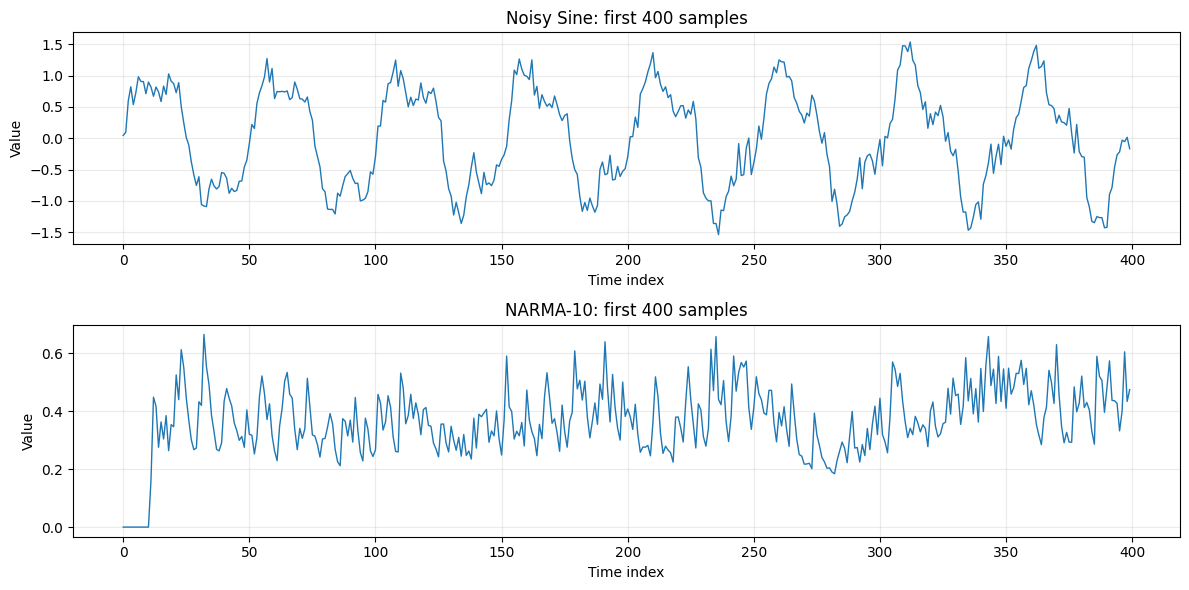

Combined data-generation time: 0.0054 seconds


In [3]:
def generate_noisy_sine(n=SERIES_LENGTH, seed=SEED, noise_std=0.15):
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=np.float32)
    clean = np.sin(2*np.pi*t/50.0) + 0.35*np.sin(2*np.pi*t/17.0)
    noise = rng.normal(0.0, noise_std, size=n)
    return (clean + noise).astype(np.float32)

def generate_narma10(n=SERIES_LENGTH, seed=SEED):
    rng = np.random.default_rng(seed)
    u = rng.uniform(0.0, NARMA_INPUT_MAX, size=n).astype(np.float64)
    y = np.zeros(n, dtype=np.float64)
    # Standard NARMA-10 recurrence. Initial values are zero.
    for t in range(10, n-1):
        y[t+1] = (
            0.3*y[t]
            + 0.05*y[t]*np.sum(y[t-9:t+1])
            + 1.5*u[t-9]*u[t]
            + 0.1
        )
    return y.astype(np.float32)

gen_start = time.perf_counter()
series_data = {
    "Noisy Sine": generate_noisy_sine(),
    "NARMA-10": generate_narma10()
}
generation_seconds = time.perf_counter() - gen_start

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, (name, values) in zip(axes, series_data.items()):
    ax.plot(values[:400], linewidth=1)
    ax.set_title(f"{name}: first 400 samples")
    ax.set_xlabel("Time index")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Combined data-generation time: {generation_seconds:.4f} seconds")

## 3. Chronological split first, then create windows

The raw series is divided into 70% training, 15% validation and 15% test partitions in chronological order. Only after splitting are context/target windows made independently within each partition. The target is the sample immediately after the input context.

In [4]:
def chronological_split(values, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    n = len(values)
    i_train = int(n * train_frac)
    i_val = int(n * (train_frac + val_frac))
    return values[:i_train], values[i_train:i_val], values[i_val:]

def make_windows(partition, seq_len=SEQ_LEN):
    X, y = [], []
    for i in range(len(partition) - seq_len):
        X.append(partition[i:i+seq_len])
        y.append(partition[i+seq_len])
    return np.asarray(X, dtype=np.float32)[..., None], np.asarray(y, dtype=np.float32)

partitioned = {}
for name, values in series_data.items():
    tr, va, te = chronological_split(values)
    partitioned[name] = {
        "train": make_windows(tr),
        "validation": make_windows(va),
        "test": make_windows(te),
        "raw_parts": {"train": tr, "validation": va, "test": te}
    }
    print(name, {k: v[0].shape for k,v in partitioned[name].items() if k != "raw_parts"})

Noisy Sine {'train': (416, 4, 1), 'validation': (86, 4, 1), 'test': (86, 4, 1)}
NARMA-10 {'train': (416, 4, 1), 'validation': (86, 4, 1), 'test': (86, 4, 1)}


## 4. PyTorch datasets and data loaders

In [5]:
class WindowDataset(Dataset):
    def __init__(self, pair):
        self.X = torch.tensor(pair[0], dtype=torch.float32)
        self.y = torch.tensor(pair[1], dtype=torch.float32).unsqueeze(-1)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def make_loaders(dataset_name):
    parts = partitioned[dataset_name]
    train_ds = WindowDataset(parts["train"])
    val_ds = WindowDataset(parts["validation"])
    test_ds = WindowDataset(parts["test"])
    generator = torch.Generator().manual_seed(SEED)
    return (
        DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator, pin_memory=PIN_MEMORY),
        DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY),
        DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)
    )

## 5. Classical self-attention model

The classical model uses learned query, key and value projections, scaled dot-product self-attention, a residual connection, layer normalization, and a regression head that forecasts one scalar.

In [6]:
class ClassicalSelfAttention(nn.Module):
    def __init__(self, d_model=8):
        super().__init__()
        self.input_proj = nn.Linear(1, d_model)
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, 16), nn.GELU(), nn.Linear(16, d_model))
        self.head = nn.Sequential(nn.Linear(d_model, 8), nn.GELU(), nn.Linear(8, 1))
        self.d_model = d_model

    def forward(self, x, return_attention=False):
        h = self.input_proj(x)
        q, k, v = self.q_proj(h), self.k_proj(h), self.v_proj(h)
        scores = torch.matmul(q, k.transpose(1,2)) / math.sqrt(self.d_model)
        attn = torch.softmax(scores, dim=-1)
        context = torch.matmul(attn, v)
        h = self.norm(h + context)
        h = self.norm(h + self.ff(h))
        prediction = self.head(h[:, -1, :])
        return (prediction, attn) if return_attention else prediction

## 6. Quantum overlap-attention circuit

Each token is mapped to two bounded angles. For every query/key token pair, a two-qubit circuit:
1. encodes the query angles with Y rotations,
2. applies a trainable entangling variational layer,
3. applies the inverse key encoding,
4. measures the all-zero projector probability.

This probability becomes a nonnegative quantum attention score. The attention weights are normalized across keys with softmax. Values and the forecast head remain classical.

The circuit is deliberately small so the pairwise attention experiment is feasible on a notebook simulator. Analytic expectation values are used during training; a separate finite-shot pass is measured later.

In [7]:
dev_analytic = qml.device("default.qubit", wires=N_QUBITS, shots=None)

@qml.qnode(dev_analytic, interface="torch", diff_method="backprop")
def quantum_overlap_score(query_angles, key_angles, weights):
    qml.AngleEmbedding(query_angles, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    qml.adjoint(qml.AngleEmbedding)(key_angles, wires=range(N_QUBITS), rotation="Y")
    return qml.expval(qml.Projector([0, 0], wires=range(N_QUBITS)))

class QuantumSelfAttention(nn.Module):
    def __init__(self, d_model=8):
        super().__init__()
        self.input_proj = nn.Linear(1, d_model)
        self.q_proj = nn.Linear(d_model, N_QUBITS)
        self.k_proj = nn.Linear(d_model, N_QUBITS)
        self.v_proj = nn.Linear(d_model, d_model)
        self.q_weights = nn.Parameter(0.01 * torch.randn(Q_DEPTH, N_QUBITS, 3))
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, 16), nn.GELU(), nn.Linear(16, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Linear(d_model, 8), nn.GELU(), nn.Linear(8, 1))

    def _angles(self, z):
        return torch.pi * torch.tanh(z)

    def forward(self, x, return_attention=False):
        h = self.input_proj(x)
        q = self._angles(self.q_proj(h))
        k = self._angles(self.k_proj(h))
        v = self.v_proj(h)

        batch, length, _ = q.shape
        score_batches = []
        for b in range(batch):
            rows = []
            for i in range(length):
                row = []
                for j in range(length):
                    # QNode call is differentiable with respect to q, k and weights.
                    # default.qubit is CPU-based. Move circuit inputs/weights to CPU;
                    # .to("cpu") remains differentiable, so gradients flow back to GPU.
                    q_cpu = q[b, i].to("cpu")
                    k_cpu = k[b, j].to("cpu")
                    weights_cpu = self.q_weights.to("cpu")
                    score = quantum_overlap_score(q_cpu, k_cpu, weights_cpu)
                    row.append(score)
                rows.append(torch.stack(row))
            score_batches.append(torch.stack(rows))
        quantum_scores = torch.stack(score_batches).to(
            device=v.device, dtype=v.dtype
        )
        # Clamp away exact zeros before log; softmax(log(score)) normalizes scores.
        logits = torch.log(torch.clamp(quantum_scores, min=1e-7))
        attn = torch.softmax(logits, dim=-1)
        context = torch.matmul(attn, v)
        h = self.norm1(h + context)
        h = self.norm2(h + self.ff(h))
        prediction = self.head(h[:, -1, :])
        return (prediction, attn) if return_attention else prediction

print("Quantum circuit:", qml.draw(quantum_overlap_score)(
    torch.tensor([0.1,0.2]), torch.tensor([0.3,0.4]),
    torch.zeros(Q_DEPTH, N_QUBITS, 3)
))

Quantum circuit: 0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─╭AngleEmbedding(M2)†─┤ ╭<|00⟩⟨00|>
1: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─╰AngleEmbedding(M2)†─┤ ╰<|00⟩⟨00|>

M0 = 
tensor([0.1000, 0.2000])
M1 = 
tensor([[[0., 0., 0.],
         [0., 0., 0.]]])
M2 = 
tensor([0.3000, 0.4000])


## 7. Training, validation early stopping and prediction helpers

In [8]:
def _sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_count = 0.0, 0
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=PIN_MEMORY)
        yb = yb.to(DEVICE, non_blocking=PIN_MEMORY)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            pred = model(xb)
            loss = nn.functional.mse_loss(pred, yb)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(xb)
        total_count += len(xb)
    return total_loss / max(total_count, 1)


def fit_model(model, train_loader, val_loader, epochs=EPOCHS):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_state, best_val, bad_epochs = None, float("inf"), 0
    history = {"train_loss": [], "val_loss": []}
    _sync_device()
    start = time.perf_counter()
    for epoch in range(epochs):
        train_loss = run_epoch(model, train_loader, optimizer)
        val_loss = run_epoch(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
        if bad_epochs >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    _sync_device()
    return history, time.perf_counter() - start


def predict_model(model, loader, return_attention=False):
    model.eval()
    preds, targets, maps = [], [], []
    _sync_device()
    start = time.perf_counter()
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=PIN_MEMORY)
            yb = yb.to(DEVICE, non_blocking=PIN_MEMORY)
            if return_attention:
                p, a = model(xb, return_attention=True)
                maps.append(a.detach().cpu().numpy())
            else:
                p = model(xb)
            preds.append(p.detach().cpu().numpy())
            targets.append(yb.detach().cpu().numpy())
    _sync_device()
    elapsed = time.perf_counter() - start
    return np.concatenate(preds).ravel(), np.concatenate(targets).ravel(), elapsed, (np.concatenate(maps) if maps else None)


def regression_metrics(y_true, y_pred):
    residual = y_pred - y_true
    mae = np.mean(np.abs(residual))
    rmse = np.sqrt(np.mean(residual**2))
    denom = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1.0 - np.sum(residual**2)/denom if denom > 0 else np.nan
    return {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2),
            "residual_bias": float(np.mean(residual))}


## 8. Train both models on both generated datasets

In [10]:
LEARNING_RATE = 0.001

experiment_results = {}
history_results = {}
metric_rows = []

for dataset_name in partitioned:
    train_loader, val_loader, test_loader = make_loaders(dataset_name)
    for model_name, model_class in [
        ("Classical self-attention", ClassicalSelfAttention),
        ("Quantum self-attention", QuantumSelfAttention)
    ]:
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        model = model_class().to(DEVICE)
        print(f"Training {model_name} on PyTorch device: {DEVICE}")
        history, train_seconds = fit_model(model, train_loader, val_loader)
        y_pred, y_true, infer_seconds, attn_maps = predict_model(
            model, test_loader, return_attention=True
        )
        metrics = regression_metrics(y_true, y_pred)
        key = (dataset_name, model_name)
        experiment_results[key] = {
            "model": model, "y_true": y_true, "y_pred": y_pred,
            "attention_maps": attn_maps, "metrics": metrics,
            "training_seconds": train_seconds, "inference_seconds": infer_seconds
        }
        history_results[key] = history
        metric_rows.append({
            "dataset": dataset_name, "model": model_name,
            **metrics, "training_time_seconds": train_seconds,
            "inference_time_seconds": infer_seconds,
            "inference_latency_ms_per_sample": infer_seconds / len(y_true) * 1000
        })
        print(dataset_name, model_name, metrics, f"train={train_seconds:.2f}s")

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(5))

Training Classical self-attention on PyTorch device: cuda:0
Noisy Sine Classical self-attention {'MAE': 0.27399942278862, 'RMSE': 0.33659234642982483, 'R2': 0.817141592502594, 'residual_bias': 0.02619054727256298} train=1.30s
Training Quantum self-attention on PyTorch device: cuda:0
Noisy Sine Quantum self-attention {'MAE': 0.25421616435050964, 'RMSE': 0.32944682240486145, 'R2': 0.8248229622840881, 'residual_bias': 0.05007340759038925} train=191.80s
Training Classical self-attention on PyTorch device: cuda:0
NARMA-10 Classical self-attention {'MAE': 0.06741709262132645, 'RMSE': 0.08192656934261322, 'R2': 0.09692835807800293, 'residual_bias': -0.009441385045647621} train=0.68s
Training Quantum self-attention on PyTorch device: cuda:0
NARMA-10 Quantum self-attention {'MAE': 0.06628966331481934, 'RMSE': 0.0791054293513298, 'R2': 0.15805214643478394, 'residual_bias': -0.0006491701351478696} train=184.19s


,dataset,model,MAE,RMSE,R2,residual_bias,training_time_seconds,inference_time_seconds,inference_latency_ms_per_sample
0,Noisy Sine,Classical self-attention,0.27400,0.33659,0.81714,0.02619,1.30422,0.01366,0.15879
1,Noisy Sine,Quantum self-attention,0.25422,0.32945,0.82482,0.05007,191.79610,6.50280,75.61391
2,NARMA-10,Classical self-attention,0.06742,0.08193,0.09693,-0.00944,0.68274,0.01255,0.14597
3,NARMA-10,Quantum self-attention,0.06629,0.07911,0.15805,-0.00065,184.18976,5.57780,64.85815


## 9. Training curves

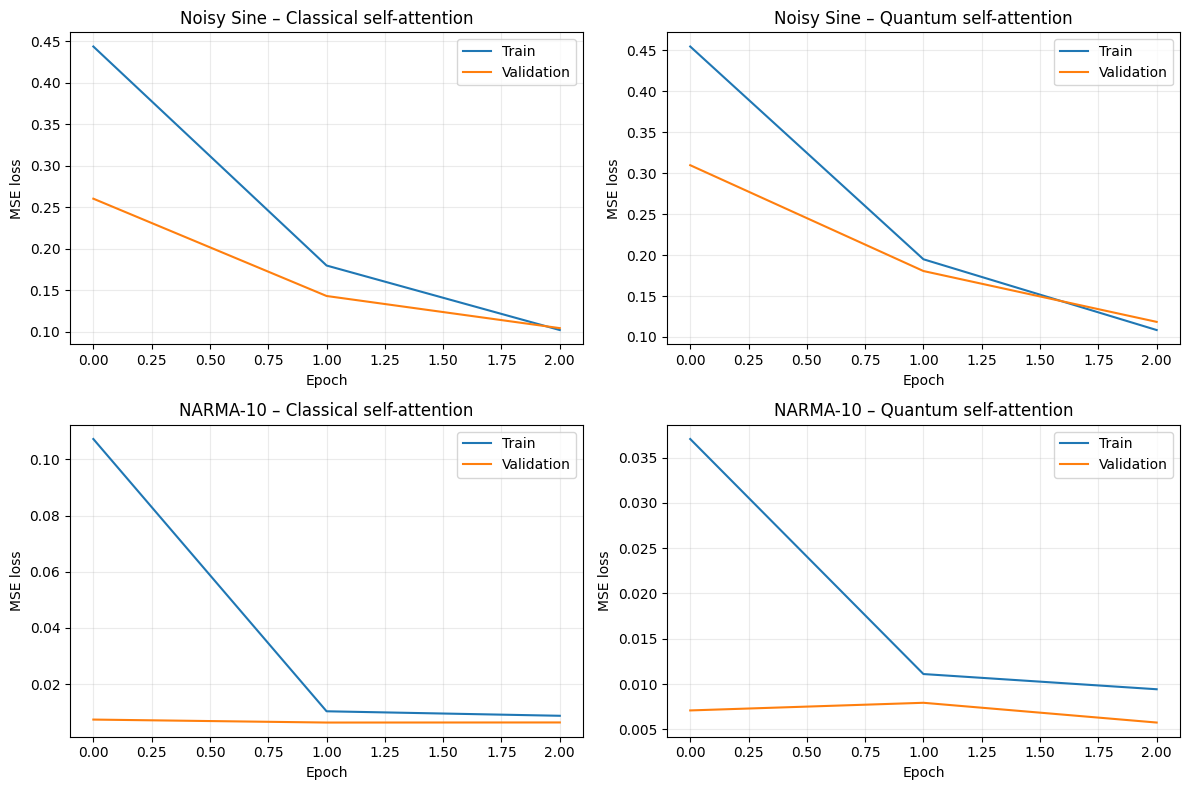

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (key, hist) in zip(axes.ravel(), history_results.items()):
    ax.plot(hist["train_loss"], label="Train")
    ax.plot(hist["val_loss"], label="Validation")
    ax.set_title(f"{key[0]} – {key[1]}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Actual vs predicted and residual plots

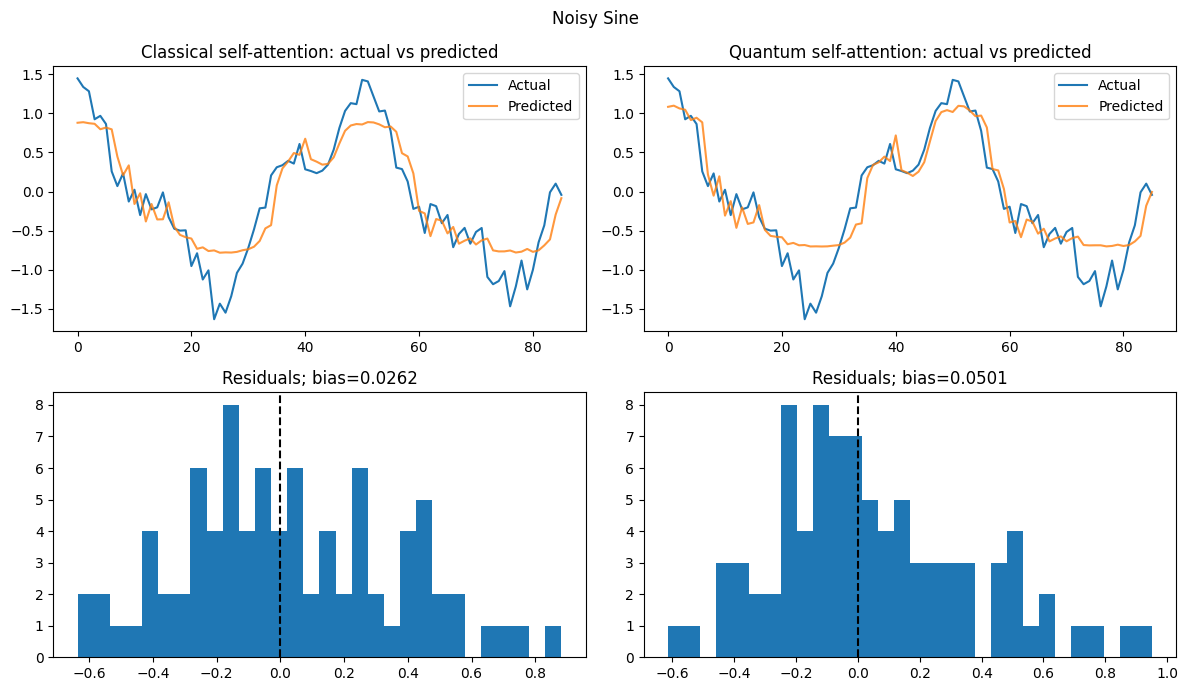

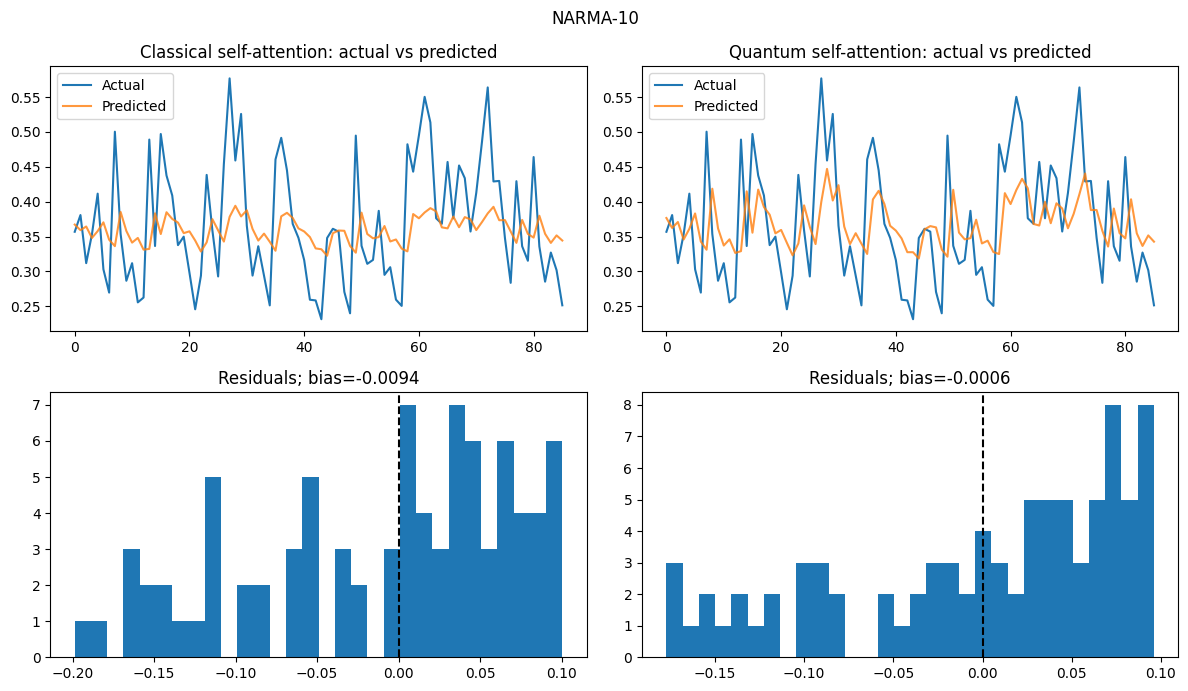

In [13]:
for dataset_name in partitioned:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for col, model_name in enumerate(["Classical self-attention", "Quantum self-attention"]):
        r = experiment_results[(dataset_name, model_name)]
        axes[0,col].plot(r["y_true"][:250], label="Actual")
        axes[0,col].plot(r["y_pred"][:250], label="Predicted", alpha=0.8)
        axes[0,col].set_title(f"{model_name}: actual vs predicted")
        axes[0,col].legend()
        residual = r["y_pred"] - r["y_true"]
        axes[1,col].hist(residual, bins=30)
        axes[1,col].axvline(0, color="black", linestyle="--")
        axes[1,col].set_title(f"Residuals; bias={residual.mean():.4f}")
    fig.suptitle(dataset_name)
    plt.tight_layout()
    plt.show()

## 11. Attention-map stability

We measure stability by comparing attention maps for the same test windows before and after adding small Gaussian perturbations to the input windows. The reported score is the mean cosine similarity between flattened attention maps; values closer to 1 indicate greater stability under this particular perturbation test.

This is a diagnostic, not a universal measure of attention quality.

In [14]:
def attention_stability(model, X, perturb_std=NOISE_STABILITY, max_samples=64):
    X = torch.tensor(X[:max_samples], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        _, a1 = model(X, return_attention=True)
        noisy = X + perturb_std * torch.randn_like(X)
        _, a2 = model(noisy, return_attention=True)
    a1 = a1.reshape(len(X), -1).cpu().numpy()
    a2 = a2.reshape(len(X), -1).cpu().numpy()
    sims = []
    for x, y in zip(a1, a2):
        denom = np.linalg.norm(x)*np.linalg.norm(y)
        sims.append(float(np.dot(x,y)/denom) if denom else np.nan)
    return float(np.nanmean(sims)), float(np.nanstd(sims))

stability_rows = []
for dataset_name in partitioned:
    X_test = partitioned[dataset_name]["test"][0]
    for model_name in ["Classical self-attention", "Quantum self-attention"]:
        model = experiment_results[(dataset_name, model_name)]["model"]
        mean_sim, std_sim = attention_stability(model, X_test)
        stability_rows.append({
            "dataset": dataset_name, "model": model_name,
            "attention_map_stability_mean_cosine": mean_sim,
            "attention_map_stability_std": std_sim
        })
stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(5))

,dataset,model,attention_map_stability_mean_cosine,attention_map_stability_std
0,Noisy Sine,Classical self-attention,0.99999,0.00002
1,Noisy Sine,Quantum self-attention,0.99972,0.00065
2,NARMA-10,Classical self-attention,1.00000,0.00000
3,NARMA-10,Quantum self-attention,0.99789,0.00606


## 12. Quantum circuit resource accounting

The attention circuit is called once for each query/key pair. For a batch of size B and sequence length L, the forward-pass pair count is B × L². This is an **evaluation proxy** for the number of pairwise quantum-node calls. Gradient computation may invoke additional simulator work; exact low-level simulator executions are not inferred from this proxy.

The circuit uses analytic expectation values during training. We separately run a finite-shot attention-map pass on a small test subset. That pass measures quantum attention scores with the configured shots and then normalizes them into attention maps.

In [15]:
def quantum_circuit_resource_summary():
    q = quantum_overlap_score
    sample_q = torch.tensor([0.1,0.2])
    sample_k = torch.tensor([0.2,0.3])
    sample_w = torch.zeros(Q_DEPTH, N_QUBITS, 3)
    try:
        decomposed = qml.transforms.decompose(
            q, gate_set={"RX","RY","RZ","CNOT"}
        )
        specs = qml.specs(decomposed)(sample_q, sample_k, sample_w)
        res = specs["resources"]
        return res.depth, res.num_gates, dict(res.gate_types)
    except Exception as e:
        return np.nan, np.nan, {"resource_introspection_error": str(e)}

circuit_depth, gate_count, gate_types = quantum_circuit_resource_summary()
resource_rows = []
for dataset_name in partitioned:
    q_result = experiment_results[(dataset_name, "Quantum self-attention")]
    test_n = len(q_result["y_true"])
    n_batches = math.ceil(len(partitioned[dataset_name]["train"][1]) / BATCH_SIZE)
    # Epoch count is the maximum; early stopping means actual epochs may be fewer.
    trained_epochs = len(history_results[(dataset_name, "Quantum self-attention")]["train_loss"])
    train_batches = trained_epochs * n_batches
    pair_calls_per_batch = BATCH_SIZE * SEQ_LEN * SEQ_LEN
    resource_rows.append({
        "dataset": dataset_name,
        "qubits": N_QUBITS,
        "modes": "N/A (qubit circuit)",
        "circuit_depth_decomposed": circuit_depth,
        "decomposed_gate_count_per_pair": gate_count,
        "decomposed_gate_types": json.dumps(gate_types),
        "variational_layers": Q_DEPTH,
        "trainable_quantum_parameters": Q_DEPTH*N_QUBITS*3,
        "shots_training": "analytic (shots=None)",
        "finite_shots_per_pair": Q_SHOTS,
        "test_samples_in_finite_shot_pass": min(test_n, 32),
        "finite_shot_pair_measurements": min(test_n,32)*SEQ_LEN*SEQ_LEN,
        "finite_shot_measurement_shots_total": min(test_n,32)*SEQ_LEN*SEQ_LEN*Q_SHOTS,
        "training_pairwise_qnode_calls_proxy": train_batches*pair_calls_per_batch,
        "training_circuit_evaluations_exact": "Not instrumented; analytic simulator backprop",
        "training_time_seconds": q_result["training_seconds"],
        "inference_time_seconds": q_result["inference_seconds"],
        "inference_latency_ms_per_sample": q_result["inference_seconds"]/test_n*1000,
        "generation_time_seconds_shared": generation_seconds
    })
resource_df = pd.DataFrame(resource_rows)
display(resource_df)

,dataset,qubits,modes,circuit_depth_decomposed,decomposed_gate_count_per_pair,decomposed_gate_types,variational_layers,trainable_quantum_parameters,shots_training,finite_shots_per_pair,test_samples_in_finite_shot_pass,finite_shot_pair_measurements,finite_shot_measurement_shots_total,training_pairwise_qnode_calls_proxy,training_circuit_evaluations_exact,training_time_seconds,inference_time_seconds,inference_latency_ms_per_sample,generation_time_seconds_shared
0,Noisy Sine,2,N/A (qubit circuit),7,12,"{""RY"": 6, ""RZ"": 4, ""CNOT"": 2}",1,6,analytic (shots=None),128,32,512,65536,19968,Not instrumented; analytic simulator backprop,191.796095,6.502796,75.613909,0.005445
1,NARMA-10,2,N/A (qubit circuit),7,12,"{""RY"": 6, ""RZ"": 4, ""CNOT"": 2}",1,6,analytic (shots=None),128,32,512,65536,19968,Not instrumented; analytic simulator backprop,184.189758,5.577801,64.858150,0.005445


## 13. Finite-shot quantum attention-map pass

In [16]:
dev_finite = qml.device("default.qubit", wires=N_QUBITS, shots=Q_SHOTS)

@qml.qnode(dev_finite)
def finite_shot_overlap_score(query_angles, key_angles, weights):
    qml.AngleEmbedding(query_angles, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    qml.adjoint(qml.AngleEmbedding)(key_angles, wires=range(N_QUBITS), rotation="Y")
    return qml.expval(qml.Projector([0,0], wires=range(N_QUBITS)))

finite_shot_rows = []
finite_shot_attention = {}

for dataset_name in partitioned:
    model = experiment_results[(dataset_name, "Quantum self-attention")]["model"]
    X_test = torch.tensor(partitioned[dataset_name]["test"][0][:32], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        h = model.input_proj(X_test)
        q_angles = torch.pi * torch.tanh(model.q_proj(h))
        k_angles = torch.pi * torch.tanh(model.k_proj(h))
        q_weights = model.q_weights.detach().to("cpu")
        q_angles = q_angles.detach().to("cpu")
        k_angles = k_angles.detach().to("cpu")

    start = time.perf_counter()
    all_maps = []
    with torch.no_grad():
        for b in range(len(X_test)):
            score_rows = []
            for i in range(SEQ_LEN):
                row = []
                for j in range(SEQ_LEN):
                    row.append(finite_shot_overlap_score(
                        q_angles[b,i], k_angles[b,j], q_weights
                    ))
                score_rows.append(torch.stack(row))
            scores = torch.stack(score_rows)
            attn = torch.softmax(torch.log(torch.clamp(scores, min=1e-7)), dim=-1)
            all_maps.append(attn.cpu().numpy())
    elapsed = time.perf_counter() - start
    finite_shot_attention[dataset_name] = np.asarray(all_maps)
    finite_shot_rows.append({
        "dataset": dataset_name,
        "shots_per_pair": Q_SHOTS,
        "samples": len(X_test),
        "pair_circuits": len(X_test)*SEQ_LEN*SEQ_LEN,
        "shot_measurement_count": len(X_test)*SEQ_LEN*SEQ_LEN*Q_SHOTS,
        "finite_shot_attention_pass_seconds": elapsed,
        "time_per_sample_ms": elapsed/len(X_test)*1000
    })

finite_shot_df = pd.DataFrame(finite_shot_rows)
display(finite_shot_df)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


,dataset,shots_per_pair,samples,pair_circuits,shot_measurement_count,finite_shot_attention_pass_seconds,time_per_sample_ms
0,Noisy Sine,128,32,512,65536,4.335827,135.494601
1,NARMA-10,128,32,512,65536,5.438604,169.956367


## 14. Visualize attention maps

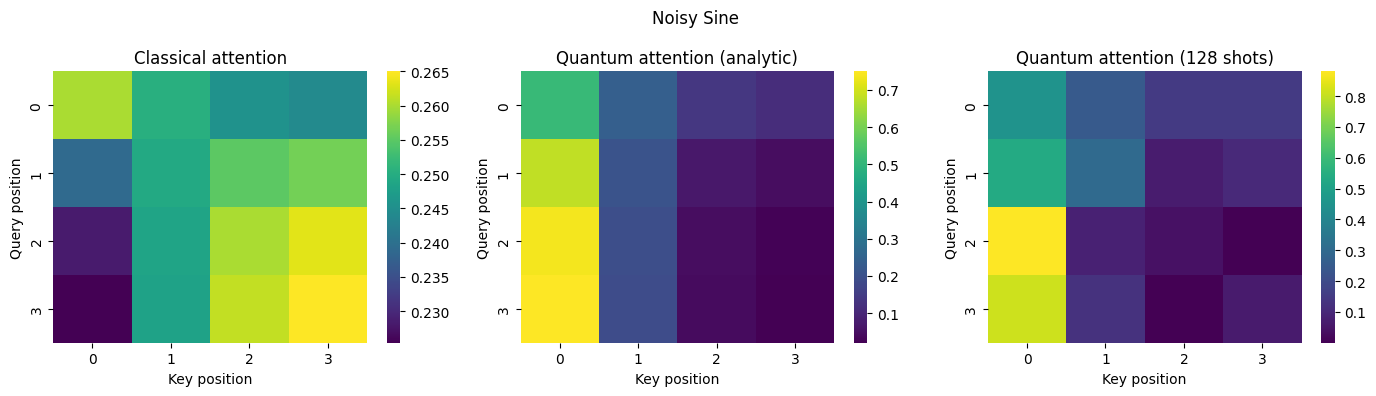

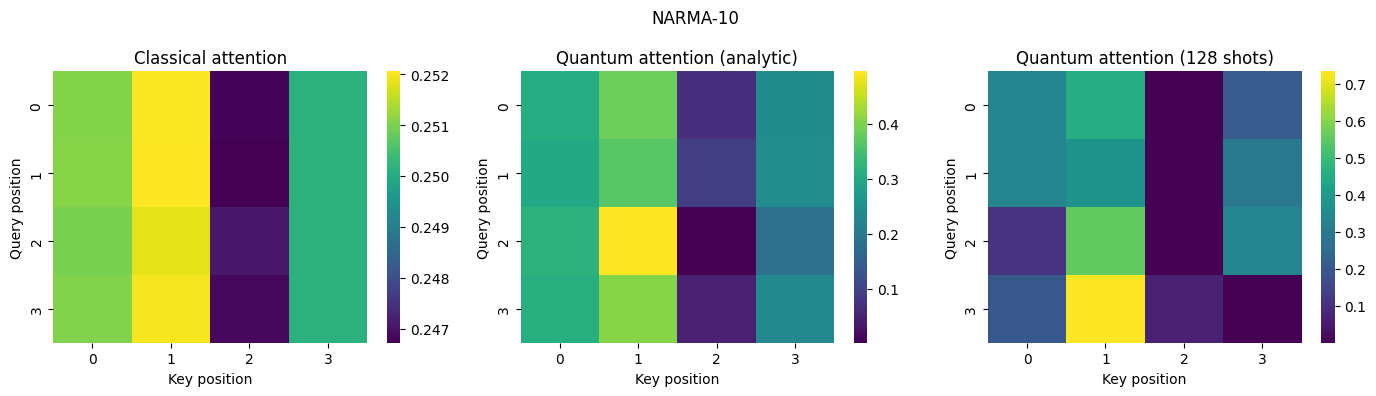

In [17]:
for dataset_name in partitioned:
    classical_map = experiment_results[(dataset_name, "Classical self-attention")]["attention_maps"]
    quantum_map = experiment_results[(dataset_name, "Quantum self-attention")]["attention_maps"]
    finite_map = finite_shot_attention[dataset_name]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    sns.heatmap(classical_map[0], ax=axes[0], cmap="viridis")
    axes[0].set_title("Classical attention")
    sns.heatmap(quantum_map[0], ax=axes[1], cmap="viridis")
    axes[1].set_title("Quantum attention (analytic)")
    sns.heatmap(finite_map[0], ax=axes[2], cmap="viridis")
    axes[2].set_title(f"Quantum attention ({Q_SHOTS} shots)")
    for ax in axes:
        ax.set_xlabel("Key position")
        ax.set_ylabel("Query position")
    fig.suptitle(dataset_name)
    plt.tight_layout()
    plt.show()

## 15. Combined result tables and comparison plots

,dataset,model,MAE,RMSE,R2,residual_bias,training_time_seconds,inference_time_seconds,inference_latency_ms_per_sample,attention_map_stability_mean_cosine,attention_map_stability_std
0,Noisy Sine,Classical self-attention,0.27400,0.33659,0.81714,0.02619,1.30422,0.01366,0.15879,0.99999,0.00002
1,Noisy Sine,Quantum self-attention,0.25422,0.32945,0.82482,0.05007,191.79610,6.50280,75.61391,0.99972,0.00065
2,NARMA-10,Classical self-attention,0.06742,0.08193,0.09693,-0.00944,0.68274,0.01255,0.14597,1.00000,0.00000
3,NARMA-10,Quantum self-attention,0.06629,0.07911,0.15805,-0.00065,184.18976,5.57780,64.85815,0.99789,0.00606


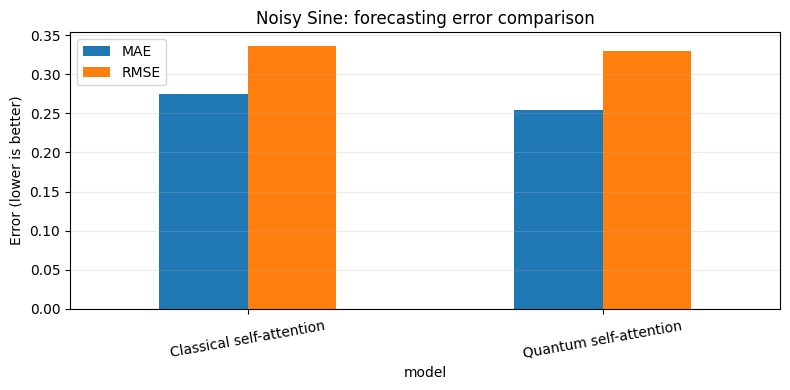

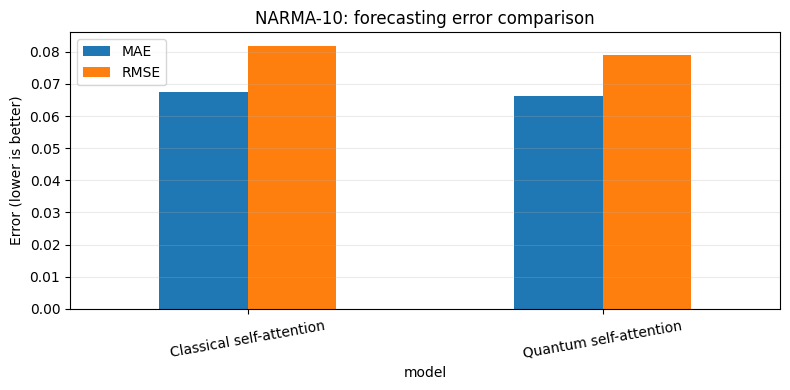

In [18]:
full_metrics_df = metrics_df.merge(stability_df, on=["dataset","model"], how="left")
display(full_metrics_df.round(5))

for dataset_name in partitioned:
    subset = full_metrics_df[full_metrics_df.dataset == dataset_name]
    ax = subset.set_index("model")[["MAE","RMSE"]].plot(kind="bar", figsize=(8,4))
    ax.set_title(f"{dataset_name}: forecasting error comparison")
    ax.set_ylabel("Error (lower is better)")
    ax.tick_params(axis="x", rotation=10)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 16. Export results

In [19]:
metrics_path = OUT_DIR / "forecast_metrics.csv"
resources_path = OUT_DIR / "quantum_resources.csv"
stability_path = OUT_DIR / "attention_stability.csv"
finite_path = OUT_DIR / "finite_shot_measurements.csv"
summary_path = OUT_DIR / "experiment_summary.json"

full_metrics_df.to_csv(metrics_path, index=False)
resource_df.to_csv(resources_path, index=False)
stability_df.to_csv(stability_path, index=False)
finite_shot_df.to_csv(finite_path, index=False)

summary = {
    "seed": SEED, "sequence_length": SEQ_LEN,
    "train_validation_test_split": [TRAIN_FRAC, VAL_FRAC, 1-TRAIN_FRAC-VAL_FRAC],
    "epochs_max": EPOCHS, "batch_size": BATCH_SIZE,
    "qubits": N_QUBITS, "shots_finite_measurement": Q_SHOTS,
    "quantum_circuit": "AngleEmbedding(Y) -> StronglyEntanglingLayers -> inverse AngleEmbedding(Y) -> all-zero projector probability",
    "training_measurement_mode": "analytic simulator",
    "metrics": full_metrics_df.to_dict(orient="records"),
    "resources": resource_df.to_dict(orient="records"),
    "finite_shot": finite_shot_df.to_dict(orient="records")
}
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print("Saved experiment outputs:")
for p in [metrics_path, resources_path, stability_path, finite_path, summary_path]:
    print(p)

Saved experiment outputs:
/content/results/forecast_metrics.csv
/content/results/quantum_resources.csv
/content/results/attention_stability.csv
/content/results/finite_shot_measurements.csv
/content/results/experiment_summary.json


## 17. Research discussion and conclusion checklist

Use the generated result tables to answer:

1. Which model has lower MAE and RMSE on noisy sine?
2. Which model has lower MAE and RMSE on NARMA-10?
3. Are R² and residual bias consistent with the error metrics?
4. Which model has more stable attention maps under the chosen perturbation?
5. How much inference latency does quantum pairwise attention add?
6. What are the decomposed circuit depth, gate count, qubit count and shot budget?
7. How many pairwise quantum-node calls are estimated per training epoch?
8. How do finite-shot attention maps differ from analytic attention maps?

### Reporting cautions
- The pairwise QNode call count is a **forward-call proxy**. Backpropagation and simulator internals may perform additional work; it is not an exact hardware circuit-evaluation count.
- Training uses analytic expectations. Finite-shot evaluation is a separate attention-map measurement pass, not finite-shot retraining.
- Attention-map stability is measured by cosine similarity under a specified Gaussian input perturbation. Report the perturbation scale and sample count.
- NARMA-10 is generated from a nonlinear recurrence and depends on the input sequence. The forecast task here predicts the next target-series value from past target values only; it is a univariate forecasting setup.
- This notebook does not demonstrate quantum advantage or physical-hardware performance.